## 1. Setup

In [16]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\kanjut\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [29]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)

# Folders for outputs
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

TensorFlow version: 2.22.0-rc0


## 2. Load the dataset

In [18]:
DATA_DIR = "dataset"          # change this if your folder is named differently
TRAIN_DIR = os.path.join(DATA_DIR, "TRAIN")
TEST_DIR = os.path.join(DATA_DIR, "TEST")

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Check that the folders exist
print("Train folder found:", os.path.isdir(TRAIN_DIR))
print("Test folder found:", os.path.isdir(TEST_DIR))
print("Train sub-folders:", os.listdir(TRAIN_DIR))

Train folder found: True
Test folder found: True
Train sub-folders: ['O', 'R']


In [19]:
# 80% of TRAIN is used for training, 20% for validation
train_data = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.2,
    subset="training",
    seed=42
)

val_data = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.2,
    subset="validation",
    seed=42
)

# TEST folder is kept separate for the final evaluation
test_data = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_data.class_names
print("Class folders:", class_names)   # ['O', 'R'] -> O = Organic, R = Recyclable

Found 22564 files belonging to 2 classes.
Using 18052 files for training.
Found 22564 files belonging to 2 classes.
Using 4512 files for validation.
Found 2513 files belonging to 2 classes.
Class folders: ['O', 'R']


['Organic', 'Recyclable']


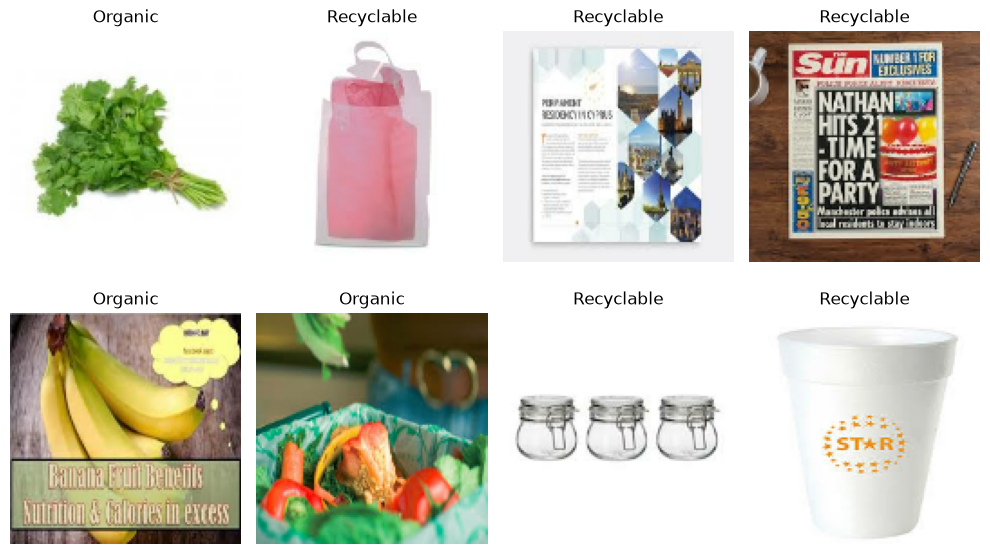

In [20]:
# Readable names for the two class folders
label_names = {"O": "Organic", "R": "Recyclable"}
display_names = [label_names.get(c, c) for c in class_names]
print(display_names)

# Show a few sample images
plt.figure(figsize=(10, 6))
for images, labels in train_data.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(display_names[int(labels[i][0])])
        plt.axis("off")
plt.tight_layout()
plt.savefig("results/sample_images.png")
plt.show()

## 3. Build the CNN model



In [21]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)              │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the model

In [22]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10


C:\Users\kanjut\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


565/565 ━━━━━━━━━━━━━━━━━━━━ 153s 269ms/step - accuracy: 0.8035 - loss: 0.4546 - val_accuracy: 0.8121 - val_loss: 0.4452
Epoch 2/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 150s 266ms/step - accuracy: 0.8420 - loss: 0.3844 - val_accuracy: 0.8322 - val_loss: 0.3825
Epoch 3/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 151s 267ms/step - accuracy: 0.8538 - loss: 0.3539 - val_accuracy: 0.8176 - val_loss: 0.4573
Epoch 4/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 152s 268ms/step - accuracy: 0.8639 - loss: 0.3326 - val_accuracy: 0.8522 - val_loss: 0.3458
Epoch 5/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 151s 267ms/step - accuracy: 0.8803 - loss: 0.3041 - val_accuracy: 0.8566 - val_loss: 0.3416
Epoch 6/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 151s 267ms/step - accuracy: 0.8893 - loss: 0.2757 - val_accuracy: 0.8557 - val_loss: 0.3527
Epoch 7/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 151s 267ms/step - accuracy: 0.9023 - loss: 0.2478 - val_accuracy: 0.8606 - val_loss: 0.3440
Epoch 8/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 151s 268ms/step - accuracy: 0.9169 - loss: 0.21

## 5. Training and validation graphs

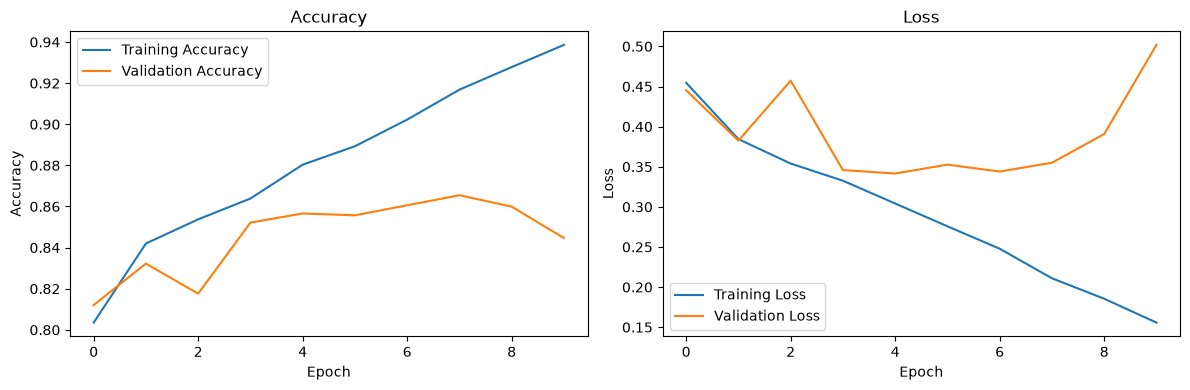

In [23]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("results/training_curves.png")
plt.show()

## 6. Evaluate on the test set

In [24]:
test_loss, test_acc = model.evaluate(test_data)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.8675 - loss: 0.4198
Test Accuracy: 0.8675
Test Loss: 0.4198


In [25]:
# Collect true labels and predictions (test_data is not shuffled, so the order matches)
y_true = np.concatenate([y.numpy() for _, y in test_data]).astype(int).ravel()
y_prob = model.predict(test_data).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Precision, recall and F1-score for each class
report = classification_report(y_true, y_pred, target_names=display_names)
print(report)

with open("results/classification_report.txt", "w") as f:
    f.write(report)

79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step
              precision    recall  f1-score   support

     Organic       0.92      0.84      0.88      1401
  Recyclable       0.82      0.90      0.86      1112

    accuracy                           0.87      2513
   macro avg       0.87      0.87      0.87      2513
weighted avg       0.87      0.87      0.87      2513



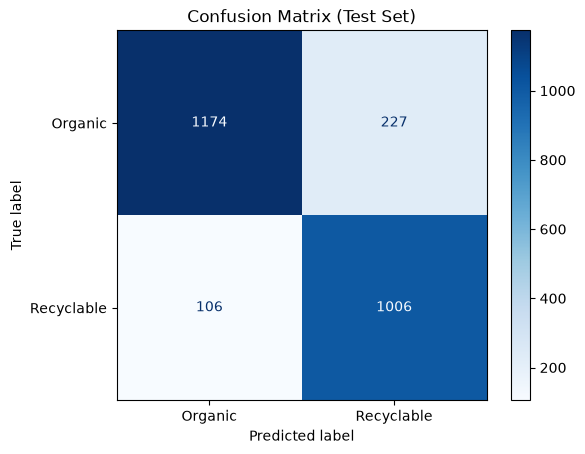

In [26]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_names)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.savefig("results/confusion_matrix.png")
plt.show()

## 7. Save the model

In [27]:
model.save("models/waste_model.keras")
print("Model trained and saved successfully.")

Model trained and saved successfully.


## 8. Predict a single image

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


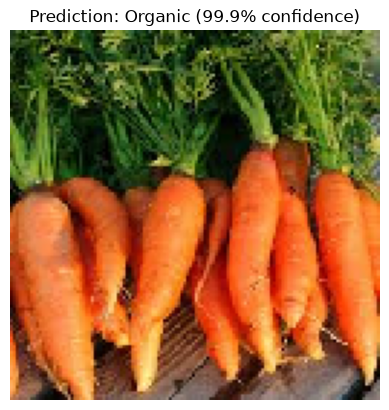

In [36]:
from tensorflow.keras.preprocessing import image

saved_model = tf.keras.models.load_model("models/waste_model.keras")

image_path = os.path.join(TEST_DIR, "O", os.listdir(os.path.join(TEST_DIR, "O"))[0])  # change to your own image

img = image.load_img(image_path, target_size=(128, 128))
img_array = np.expand_dims(image.img_to_array(img), axis=0)

prob = float(saved_model.predict(img_array)[0][0])   # probability of class index 1 (Recyclable)
pred_index = int(prob >= 0.5)
confidence = prob if pred_index == 1 else 1 - prob

plt.imshow(img)
plt.axis("off")
plt.title(f"Prediction: {display_names[pred_index]} ({confidence * 100:.1f}% confidence)")
plt.show()

In [38]:
%%writefile .gitignore

# Python cache files
__pycache__/
*.pyc

# Jupyter Notebook checkpoints
.ipynb_checkpoints/

# Virtual environments
venv/
env/
.venv/

# Dataset folder
dataset/

# Environment variables
.env

# Log files
*.log

# Operating system files
.DS_Store
Thumbs.db

Overwriting .gitignore


In [41]:
!git init

Initialized empty Git repository in C:/Users/kanjut/Downloads/files/.git/


In [42]:
!git branch -M main

In [43]:
!git config user.name "kanjutajmal"

In [44]:
!git config user.email "kanjutajmalL@example.com"